# Fragment subsampling with four seeds (Fig. 5d-e, Supp. Figs 12-13) and subsampling variability

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

`cfdna_subsampling_auc_per_fold.csv.gz`: one AUC per task x method x fragment count
x seed x subsample x CV fold. Four subsampling seeds x ten independent fragment
subsamples per seed = 40 subsamples per fragment count; the five outer folds are the
same for every subsample. Binning baselines at 10,000 genome-wide bins (~300 kb).
The published panels are seed 42 alone (10 subsamples), reproduced exactly by this
table.

**Fig. 5d-e and Supp. Figs 12-13** are the published panels with all four seeds:
same code, layout, axes and band definition. Lines are the mean over the 200 fold x
subsample AUCs; bands are the BCa 95 % CI of that mean (9,999 resamples), as
published over 50. Fig. 5e uses the published definition on the four-seed mean
curves: 100,000 divided by the first fragment count at which LEAF-1's mean AUC
reaches Bin + Length's mean AUC at 100,000 fragments (1 when never reached).
"Embedding" is named LEAF-1.

**New supplementary figure `cfdna_subsampling_variability`** answers Comment 2.m3:
each subsample's AUC is its mean over the five folds, and the figure shows the
spread across the 40 subsamples. a, pan-cancer AUC with the 2.5-97.5 % range across
subsamples; b, the paired gain LEAF-1 minus Bin + Length on the same subsample, with
that range and the 95 % bootstrap CI of the mean gain. Bootstraps resample the 40
subsamples (2,000 draws, jointly across fragment counts); patients and folds are
fixed and not resampled. Linear fragment axis as in Fig. 5d, extended down to 100
fragments (100-1,000 sit at the left edge; values in the table). The Fig. 5e gains
with bootstrap 95 % CIs are written to `cfdna_fragment_efficiency_seeds_ci.tsv`.

Panels:
- `cfdna_fragment_subsampling_seeds` (Fig. 5d), `cfdna_fragment_efficiency_seeds` (Fig. 5e)
- `cfdna_subsampling_seeds_vs_healthy`, `cfdna_subsampling_seeds_vs_other` (Supp. Figs 12-13)
- `cfdna_subsampling_variability` (new supplementary figure)
- `cfdna_subsampling_seeds_table` (supplementary table)

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Constants, data, statistics ───────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

PAPER_RC = {"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
            "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7, "xtick.labelsize": 7,
            "ytick.labelsize": 7, "legend.fontsize": 6, "axes.linewidth": 0.5,
            "xtick.major.width": 0.5, "ytick.major.width": 0.5, "lines.linewidth": 1,
            "axes.spines.top": False, "axes.spines.right": False}
# Supp. Figs 12-13 were drawn one size smaller, with their own rcParams.
SUPP_RC = {"font.family": "sans-serif",
           "font.sans-serif": ["DejaVu Sans", "Liberation Sans", "Arial", "Helvetica"],
           "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6,
           "ytick.labelsize": 6, "legend.fontsize": 5, "axes.linewidth": 0.5,
           "xtick.major.width": 0.5, "ytick.major.width": 0.5}
METHODS = ["LEAF-1", "Bin + Length", "Bin + DELFI", "Bin only"]
COLORS = {"LEAF-1": "#0072B2", "Bin + Length": "#D55E00", "Bin + DELFI": "#009E73", "Bin only": "#CC79A7"}
CANCERS = ["Bile_duct", "Breast", "Colorectal", "Gastric", "Lung", "Ovarian", "Pancreatic"]
LABELS = ["Bile duct", "Breast", "Colorectal", "Gastric", "Lung", "Ovarian", "Pancreatic"]
FULL, N_BOOT = 100000, 2000

fold = pd.read_csv(DATA / "cfdna_subsampling_auc_per_fold.csv.gz", float_precision="round_trip")
assert (fold.groupby(["target", "method", "fragment_count"]).size() == 200).all()
DEPTHS = np.array(sorted(fold.fragment_count.unique()))

# Published-style summary: mean and BCa 95% CI over the 200 fold x subsample AUCs.
def bca(v):
    ci = bootstrap((np.asarray(v),), np.mean, n_resamples=9999, method="BCa",
                   random_state=np.random.default_rng(42)).confidence_interval
    return ci.low, ci.high

rows = []
for (t, m, n), g in fold.groupby(["target", "method", "fragment_count"]):
    lo, hi = bca(g.auc)
    rows.append({"target": t, "method": m, "fragment_count": n, "auc_mean": g.auc.mean(),
                 "ci_low": lo, "ci_high": hi, "n_fold_auc": len(g)})
pooled = pd.DataFrame(rows)

# Subsample level: each subsample's AUC is its mean over the five fixed folds.
sub = fold.groupby(["target", "method", "fragment_count", "seed", "rep"]).auc.mean().rename("auc").reset_index()
MAT = {k: g.pivot_table(index=["seed", "rep"], columns="fragment_count", values="auc")[DEPTHS].to_numpy()
       for k, g in sub.groupby(["target", "method"])}
spread = (sub.groupby(["target", "method", "fragment_count"]).auc
             .agg(sd_across_subsamples="std", p2_5=lambda x: x.quantile(0.025),
                  p97_5=lambda x: x.quantile(0.975)).reset_index())
rng = np.random.default_rng(20261019)
BOOT = rng.integers(0, 40, (N_BOOT, 40))          # one set of draws shared by every statistic


def efficiency(L, B):
    """Published Fig. 5e definition, on mean curves."""
    hit = np.where(L >= B[-1])[0]
    return FULL / DEPTHS[hit[0]] if len(hit) else 1.0


def eff_with_ci(target):
    L, B = MAT[(target, "LEAF-1")], MAT[(target, "Bin + Length")]
    bs = np.array([efficiency(L[i].mean(0), B[i].mean(0)) for i in BOOT])
    return efficiency(L.mean(0), B.mean(0)), np.quantile(bs, 0.025), np.quantile(bs, 0.975), B.mean(0)[-1]

# Published panels show 1,000-100,000 fragments.
pub = pooled[pooled.fragment_count >= 1000]
print(f"{len(fold)} fold AUCs; {len(pooled)} task x method x depth cells")

432000 fold AUCs; 2160 task x method x depth cells


saved: cfdna/output/cfdna_fragment_subsampling_seeds.pdf
saved: cfdna/output/cfdna_fragment_subsampling_seeds.png
saved: cfdna/output/cfdna_fragment_subsampling_seeds.svg
saved: cfdna/output/cfdna_fragment_subsampling_seeds.tsv


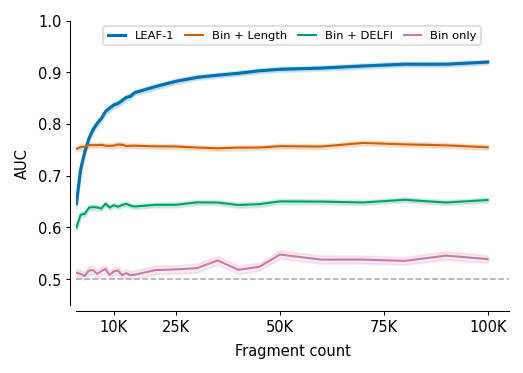

In [3]:
# ── Fig. 5d (published code; four seeds) ─────────────────────────────────────
with plt.rc_context(PAPER_RC):
    df_trend = pub[pub.target == "cancer_vs_healthy"].sort_values("fragment_count")
    fig, ax = plt.subplots(figsize=(3.5, 2.5))
    for m in METHODS:
        s = df_trend[df_trend.method == m]
        ax.fill_between(s.fragment_count, s.ci_low, s.ci_high, color=COLORS[m], alpha=0.15)
        ax.plot(s.fragment_count, s.auc_mean, color=COLORS[m], linewidth=1.5 if m == "LEAF-1" else 1.0, label=m)
    ax.axhline(0.5, color="#AAAAAA", linestyle="--", linewidth=0.75, zorder=1)
    ax.set_xlabel("Fragment count"); ax.set_ylabel("AUC")
    ax.set_xlim(1000, 105000); ax.set_ylim(0.45, 1.0)
    ax.set_xticks([10000, 25000, 50000, 75000, 100000]); ax.set_xticklabels(["10K", "25K", "50K", "75K", "100K"])
    ax.legend(loc="upper center", ncol=4, frameon=True, fontsize=5.5, facecolor="white", edgecolor="#DDDDDD",
              framealpha=0.9, columnspacing=1.0, handlelength=1.5)
    ax.spines["left"].set_position(("outward", 3)); ax.spines["bottom"].set_position(("outward", 3))
    ax.tick_params(axis="both", which="both", length=2, pad=2)
    plt.tight_layout()
    savefig(fig, OUT, "cfdna_fragment_subsampling_seeds",
            data=df_trend[["method", "fragment_count", "auc_mean", "ci_low", "ci_high", "n_fold_auc"]])
    plt.show()

saved: cfdna/output/cfdna_fragment_efficiency_seeds.pdf
saved: cfdna/output/cfdna_fragment_efficiency_seeds.png
saved: cfdna/output/cfdna_fragment_efficiency_seeds.svg
saved: cfdna/output/cfdna_fragment_efficiency_seeds.tsv


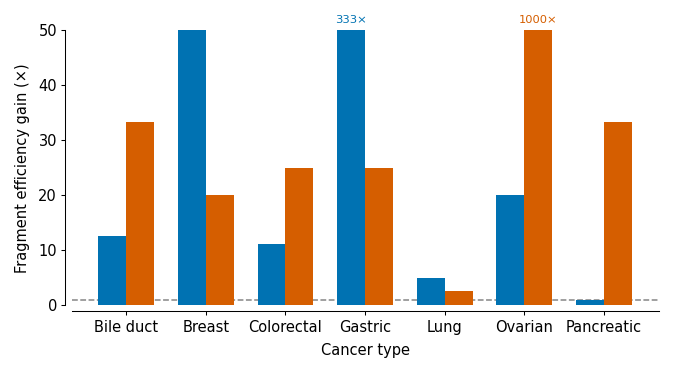

In [4]:
# ── Fig. 5e (published code; four seeds) ─────────────────────────────────────
eff_rows = []
for c, lab in zip(CANCERS, LABELS):
    for comp, comp_lab in (("healthy", "vs Healthy"), ("other_cancers", "vs Other cancers")):
        pt, lo, hi, base = eff_with_ci(f"{c}_cancer_vs_{comp}")
        eff_rows.append({"cancer": lab, "comparison": comp_lab, "gain": pt, "ci_low": lo, "ci_high": hi,
                         "bin_length_auc_at_100k": base})
eff = pd.DataFrame(eff_rows)
fold_h = eff[eff.comparison == "vs Healthy"].set_index("cancer").loc[LABELS].gain.to_numpy()
fold_oc = eff[eff.comparison == "vs Other cancers"].set_index("cancer").loc[LABELS].gain.to_numpy()

with plt.rc_context(PAPER_RC):
    CAP = 50; x = np.arange(len(CANCERS)); width = 0.35
    fig, ax = plt.subplots(figsize=(4.5, 2.5))
    ax.bar(x - width / 2, np.clip(fold_h, None, CAP), width, color=OKABE_ITO["blue"], label="vs Healthy", edgecolor="none", zorder=2)
    ax.bar(x + width / 2, np.clip(fold_oc, None, CAP), width, color=OKABE_ITO["orange"], label="vs Other cancers", edgecolor="none", zorder=2)
    for i in range(len(CANCERS)):
        if fold_h[i] > CAP:
            ax.text(x[i] - width / 2, CAP + 1, f"{fold_h[i]:.0f}\u00d7", ha="center", va="bottom", fontsize=5.5, color=OKABE_ITO["blue"])
        if fold_oc[i] > CAP:
            ax.text(x[i] + width / 2, CAP + 1, f"{fold_oc[i]:.0f}\u00d7", ha="center", va="bottom", fontsize=5.5, color=OKABE_ITO["orange"])
    ax.axhline(1, color="#888888", linestyle="--", linewidth=0.75, zorder=1)
    ax.set_xlabel("Cancer type"); ax.set_ylabel("Fragment efficiency gain (\u00d7)")
    ax.set_xticks(x); ax.set_xticklabels(LABELS, rotation=30, ha="right"); ax.set_ylim(0, CAP)
    ax.spines["left"].set_position(("outward", 3)); ax.spines["bottom"].set_position(("outward", 3))
    ax.tick_params(axis="both", which="both", length=2, pad=2)
    plt.tight_layout()
    savefig(fig, OUT, "cfdna_fragment_efficiency_seeds",
            data=pd.DataFrame({"cancer": LABELS, "fold_vs_healthy": fold_h, "fold_vs_other_cancers": fold_oc}))
    plt.show()

saved: cfdna/output/cfdna_subsampling_seeds_vs_healthy.pdf
saved: cfdna/output/cfdna_subsampling_seeds_vs_healthy.png
saved: cfdna/output/cfdna_subsampling_seeds_vs_healthy.svg
saved: cfdna/output/cfdna_subsampling_seeds_vs_healthy.tsv


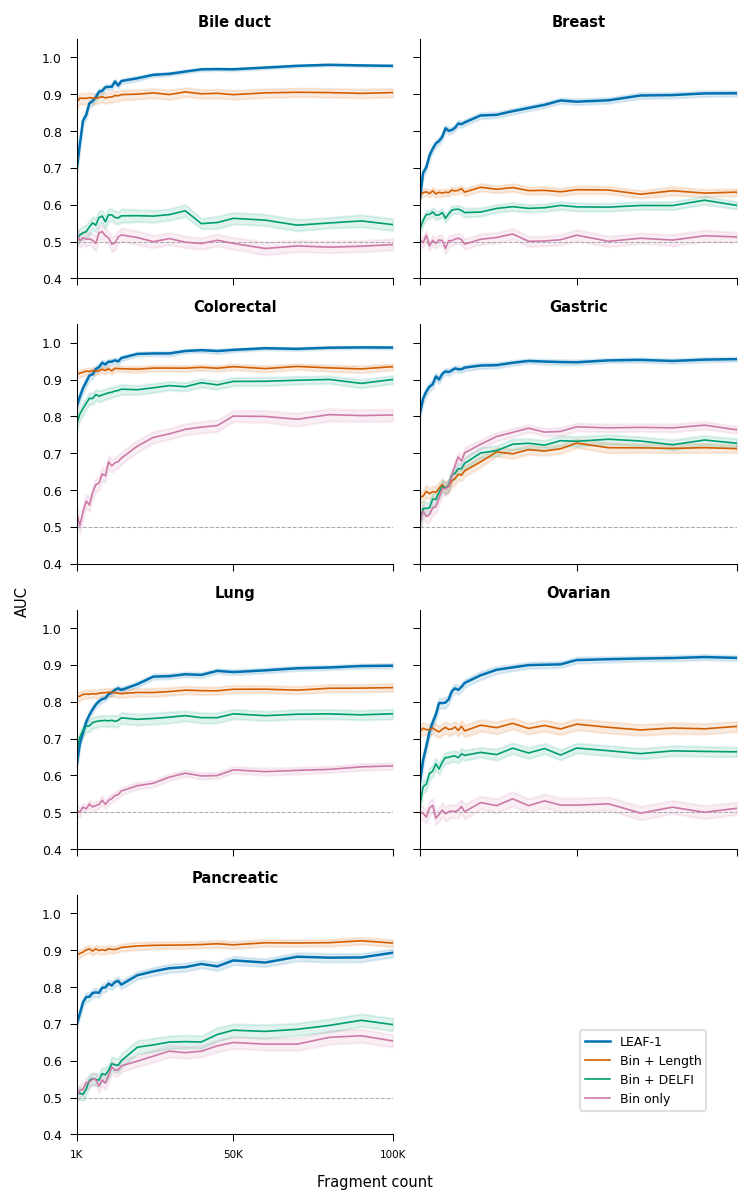

saved: cfdna/output/cfdna_subsampling_seeds_vs_other.pdf
saved: cfdna/output/cfdna_subsampling_seeds_vs_other.png
saved: cfdna/output/cfdna_subsampling_seeds_vs_other.svg
saved: cfdna/output/cfdna_subsampling_seeds_vs_other.tsv


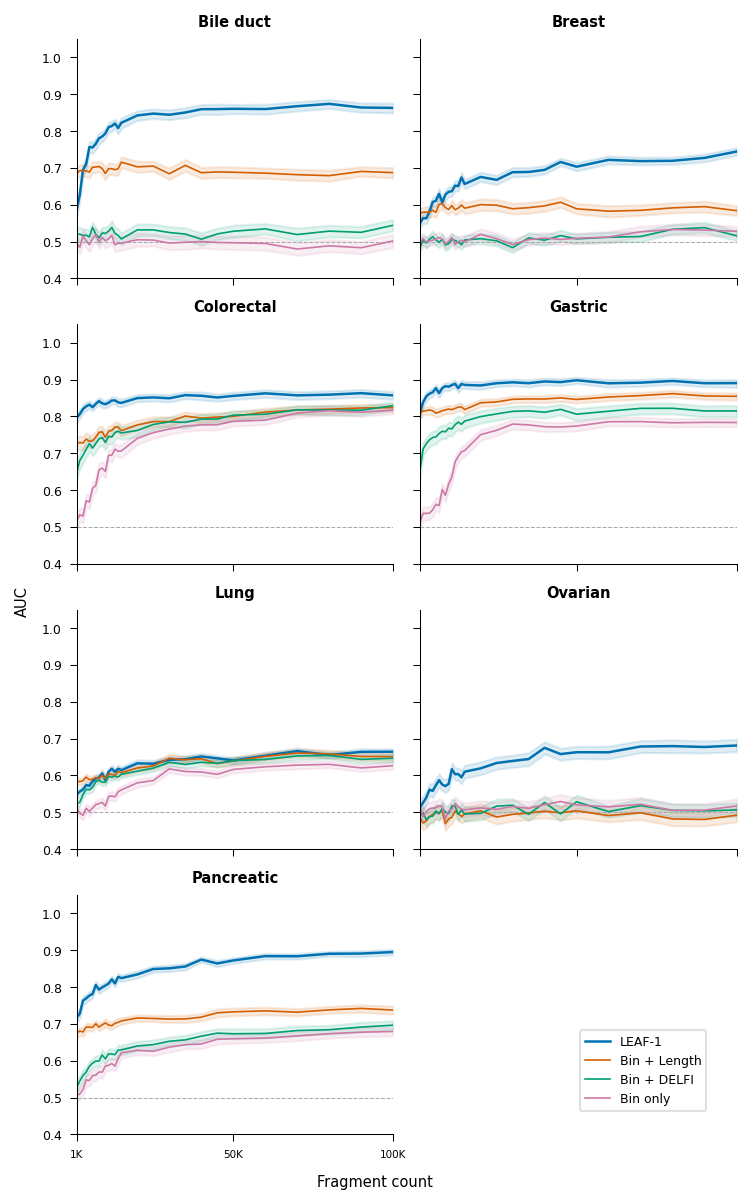

In [5]:
# ── Supp. Figs 12-13 (published code; four seeds) ────────────────────────────
def per_cancer(comp, stem):
    with plt.rc_context(SUPP_RC):
        fig, axes = plt.subplots(4, 2, figsize=(5, 8), sharey=True, sharex=True)
        flat = axes.flatten()
        for ax, c, lab in zip(flat, CANCERS, LABELS):
            p = pub[pub.target == f"{c}_cancer_vs_{comp}"]
            for m in METHODS:
                s = p[p.method == m].sort_values("fragment_count")
                ax.fill_between(s.fragment_count, s.ci_low, s.ci_high, color=COLORS[m], alpha=0.12)
                ax.plot(s.fragment_count, s.auc_mean, color=COLORS[m], linewidth=1.2 if m == "LEAF-1" else 0.8)
            ax.axhline(0.5, color="#AAAAAA", linestyle="--", linewidth=0.5, zorder=1)
            ax.set_xlim(1000, 100000); ax.set_ylim(0.4, 1.05)
            ax.set_title(lab, fontsize=7, fontweight="bold")
            ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
            ax.set_xticks([1000, 50000, 100000]); ax.set_xticklabels(["1K", "50K", "100K"], fontsize=5)
            ax.minorticks_off()
        flat[7].set_visible(False)
        fig.supylabel("AUC", fontsize=7, x=0.02); fig.supxlabel("Fragment count", fontsize=7)
        handles = [plt.Line2D([0], [0], color=COLORS[m], linewidth=1.2 if m == "LEAF-1" else 0.8, label=m)
                   for m in METHODS]
        fig.legend(handles=handles, loc="lower right", ncol=1, frameon=True, fontsize=6, facecolor="white",
                   edgecolor="#DDDDDD", framealpha=0.9, bbox_to_anchor=(0.95, 0.07))
        plt.tight_layout()
        tasks = [f"{c}_cancer_vs_{comp}" for c in CANCERS]
        savefig(fig, OUT, stem, data=pub[pub.target.isin(tasks)].sort_values(["target", "method", "fragment_count"]))
        plt.show()


per_cancer("healthy", "cfdna_subsampling_seeds_vs_healthy")
per_cancer("other_cancers", "cfdna_subsampling_seeds_vs_other")

saved: cfdna/output/cfdna_subsampling_variability.pdf
saved: cfdna/output/cfdna_subsampling_variability.png
saved: cfdna/output/cfdna_subsampling_variability.svg
saved: cfdna/output/cfdna_subsampling_variability.tsv


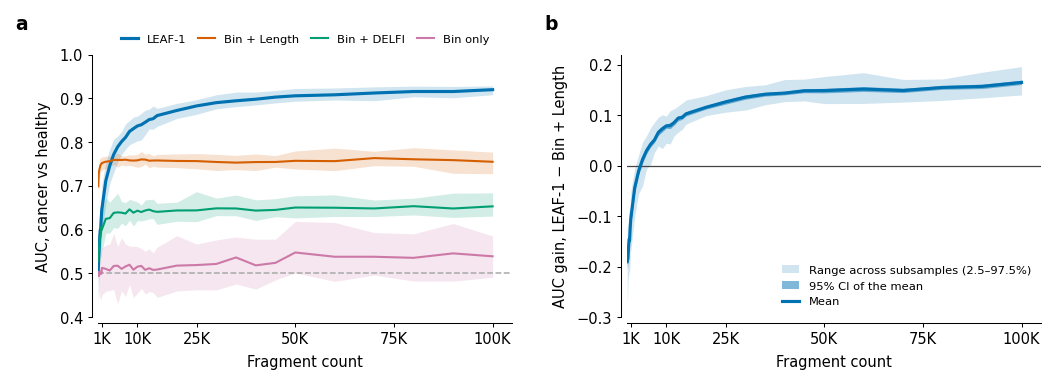

    cancer       comparison     gain  ci_low  ci_high  bin_length_auc_at_100k
 Bile duct       vs Healthy   12.500  10.000   12.500                   0.904
 Bile duct vs Other cancers   33.333  25.000   33.333                   0.687
    Breast       vs Healthy   50.000  50.000  100.000                   0.634
    Breast vs Other cancers   20.000  20.000   33.333                   0.584
Colorectal       vs Healthy   11.111  11.111   14.286                   0.935
Colorectal vs Other cancers   25.000  14.286   33.333                   0.824
   Gastric       vs Healthy  333.333 250.000  500.000                   0.713
   Gastric vs Other cancers   25.000  20.000   33.333                   0.855
      Lung       vs Healthy    5.000   5.000    7.692                   0.838
      Lung vs Other cancers    2.500   1.429    3.333                   0.651
   Ovarian       vs Healthy   20.000  16.667   25.000                   0.733
   Ovarian vs Other cancers 1000.000 250.000 1000.000           

In [6]:
# ── New supplementary figure: variability across the 40 subsamples ───────────
L, B = MAT[("cancer_vs_healthy", "LEAF-1")], MAT[("cancer_vs_healthy", "Bin + Length")]
D = L - B                                          # paired gain, 40 subsamples x depths
Dboot = np.stack([D[i].mean(0) for i in BOOT])
gain_pc = pd.DataFrame({"fragment_count": DEPTHS, "gain_mean": D.mean(0),
                        "gain_ci_low": np.quantile(Dboot, 0.025, axis=0), "gain_ci_high": np.quantile(Dboot, 0.975, axis=0),
                        "gain_p2_5": np.quantile(D, 0.025, axis=0), "gain_p97_5": np.quantile(D, 0.975, axis=0),
                        "subsamples_gain_gt_0": (D > 0).sum(0)})

def linx(ax):
    """Fig. 5d's linear fragment axis, extended to show 100-1,000 fragments at the left edge."""
    ax.set_xlim(0, 105000)
    ax.set_xticks([1000, 10000, 25000, 50000, 75000, 100000])
    ax.set_xticklabels(["1K", "10K", "25K", "50K", "75K", "100K"])

with plt.rc_context(PAPER_RC):
    fig, (a, b) = plt.subplots(1, 2, figsize=(7.0, 2.6))
    sp = spread[spread.target == "cancer_vs_healthy"]
    for m in METHODS:
        s_ = sp[sp.method == m].sort_values("fragment_count")
        a.fill_between(s_.fragment_count, s_.p2_5, s_.p97_5, color=COLORS[m], alpha=0.18, lw=0)
        a.plot(DEPTHS, MAT[("cancer_vs_healthy", m)].mean(0), color=COLORS[m],
               lw=1.5 if m == "LEAF-1" else 1.0, label=m)
    a.axhline(0.5, color="#AAAAAA", ls="--", lw=0.75, zorder=1)
    linx(a); a.set_ylim(0.4, 1.0); a.set_xlabel("Fragment count"); a.set_ylabel("AUC, cancer vs healthy")
    a.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, fontsize=5.5,
             handlelength=1.5, columnspacing=1.0)

    b.fill_between(gain_pc.fragment_count, gain_pc.gain_p2_5, gain_pc.gain_p97_5, color=COLORS["LEAF-1"],
                   alpha=0.18, lw=0, label="Range across subsamples (2.5\u201397.5%)")
    b.fill_between(gain_pc.fragment_count, gain_pc.gain_ci_low, gain_pc.gain_ci_high, color=COLORS["LEAF-1"],
                   alpha=0.5, lw=0, label="95% CI of the mean")
    b.plot(gain_pc.fragment_count, gain_pc.gain_mean, color=COLORS["LEAF-1"], lw=1.5, label="Mean")
    b.axhline(0, color="#444444", lw=0.6, zorder=1)
    linx(b); b.set_xlabel("Fragment count"); b.set_ylabel("AUC gain, LEAF-1 \u2212 Bin + Length")
    b.set_ylim(-0.3, 0.22); b.legend(frameon=False, loc="lower right", fontsize=5.5, handlelength=1.5)
    for ax, l in ((a, "a"), (b, "b")):
        ax.spines["left"].set_position(("outward", 3)); ax.spines["bottom"].set_position(("outward", 3))
        ax.tick_params(axis="both", which="both", length=2, pad=2)
        ax.text(-0.2, 1.08, l, transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom")
    plt.tight_layout(w_pad=2.5)
    savefig(fig, OUT, "cfdna_subsampling_variability", data=gain_pc)
    plt.show()

# Fig. 5e gains with bootstrap 95% CIs over the 40 subsamples (table, not drawn).
eff.to_csv(OUT / "cfdna_fragment_efficiency_seeds_ci.tsv", sep="\t", index=False, float_format="%.4f")
print(eff.round(3).to_string(index=False))

In [7]:
# ── Supplementary table and numbers for the response ──────────────────────────
gains = []
for t in sorted(sub.target.unique()):
    Lt = MAT[(t, "LEAF-1")]
    for b_ in ("Bin + Length", "Bin + DELFI", "Bin only"):
        Dt = Lt - MAT[(t, b_)]
        bm = np.stack([Dt[i].mean(0) for i in BOOT])
        for j, n in enumerate(DEPTHS):
            gains.append({"target": t, "fragment_count": n, "baseline": b_, "gain_mean": Dt[:, j].mean(),
                          "gain_ci_low": np.quantile(bm[:, j], 0.025), "gain_ci_high": np.quantile(bm[:, j], 0.975),
                          "gain_p2_5": np.quantile(Dt[:, j], 0.025), "gain_p97_5": np.quantile(Dt[:, j], 0.975),
                          "subsamples_gain_gt_0": int((Dt[:, j] > 0).sum())})
gains = pd.DataFrame(gains)
both = pooled.merge(spread, on=["target", "method", "fragment_count"])
wide = both.pivot_table(index=["target", "fragment_count"], columns="method",
                        values=["auc_mean", "ci_low", "ci_high", "sd_across_subsamples", "p2_5", "p97_5"])
wide.columns = [f"{m}__{stat}" for stat, m in wide.columns]
bl = gains[gains.baseline == "Bin + Length"].drop(columns="baseline").set_index(["target", "fragment_count"]).add_prefix("vs_bin_length__")
table = wide.join(bl).reset_index()
table.to_csv(OUT / "cfdna_subsampling_seeds_table.tsv", sep="\t", index=False, float_format="%.4f")
gains.to_csv(OUT / "cfdna_subsampling_seeds_gains_all_baselines.tsv", sep="\t", index=False, float_format="%.4f")

print(gain_pc.set_index("fragment_count").loc[[100, 1000, 3000, 4000, 5000, 6000, 10000, 100000]].round(3).to_string())
bs = np.array([efficiency(L[i].mean(0), B[i].mean(0)) for i in BOOT])
print(f"pan-cancer efficiency gain (published definition): {efficiency(L.mean(0), B.mean(0)):.1f}x "
      f"[{np.quantile(bs, .025):.1f}, {np.quantile(bs, .975):.1f}]")
sd = spread[(spread.target == "cancer_vs_healthy") & (spread.method == "LEAF-1")].set_index("fragment_count").sd_across_subsamples
print("LEAF-1 SD across subsamples:", sd.loc[[100, 1000, 5000, 10000, 100000]].round(3).to_dict())
pc = pooled[(pooled.target == "cancer_vs_healthy") & (pooled.method == "LEAF-1")].set_index("fragment_count")
print("Fig. 5d LEAF-1 CI half-width (mean over depths >=1K):", round(((pc.ci_high - pc.ci_low) / 2).loc[1000:].mean(), 4))

                gain_mean  gain_ci_low  gain_ci_high  gain_p2_5  gain_p97_5  subsamples_gain_gt_0
fragment_count                                                                                   
100                -0.190       -0.203        -0.178     -0.271      -0.123                     0
1000               -0.106       -0.117        -0.096     -0.170      -0.051                     0
3000               -0.010       -0.018        -0.002     -0.055       0.022                    16
4000                0.013        0.005         0.019     -0.040       0.047                    32
5000                0.030        0.024         0.036     -0.006       0.059                    35
6000                0.042        0.036         0.047      0.002       0.075                    39
10000               0.079        0.074         0.083      0.044       0.098                    40
100000              0.165        0.161         0.169      0.140       0.196                    40
pan-cancer efficienc